## Set Up and how to execute this Notebook

To run this notebook with full access to the PyLucene environment and your data, you need to expose the Jupyter port and mount a dedicated notebooks folder. Follow these steps:

### 1. Create the Docker Override File
In the root directory of your project (where your main `docker-compose.yml` lives), create a new file named `docker-compose.override.yml` and add the following configuration:

```yaml
version: '3.8'

services:
  pylucene:
    ports:                     
      - "8888:8888"            
    volumes:
      - ./notebooks:/app/notebooks
      - ./pylucene/src:/app/src
      - ./experiment:/app/experiment


(Note: Be sure to add docker-compose.override.yml to your .gitignore so you don't commit your local setup!)

### 2. Restart the Environment
Apply the new port mappings by restarting your Docker containers from your host terminal:

```bash
docker compose down
docker compose up -d
```
### 3. Install Requirements Inside the Container
Access the running container's terminal:

```bash
docker exec -it clef-pylucene bash
Once inside, install the necessary data science libraries:
```
```bash
pip install jupyter matplotlib seaborn
```
### 4. Launch the Jupyter Server
Finally, start the notebook server from inside the container:

```bash
jupyter notebook --ip=0.0.0.0 --port=8888 --no-browser --allow-root --notebook-dir=/app/notebooks 
```

## Exploratory Data Analysis (EDA)
The goal of this section is to extract actionable insights that will directly inform the architecture of our search engine. By understanding the shape of our data, we can tune parameters (like BM25's length penalty) and anticipate the specific retrieval challenges we need to address.

**The main research questions are:**

1. Corpus Diagnostics (The Scientific Papers)
* **Missing Data & Field Importance:** Are there missing values?
* **Length Distributions:** How is the word count distributed among Titles and Abstracts?
* **Language Distribution:** What is the native language of the papers in the collection?
* **Venue Analysis:** What are the most frequent journals or venues (`venue` field) being targeted by the claims?

2. Query Diagnostics (The Social Media Claims)
* **Length Distributions:** How long are the tweets? (Tweets are often messy; knowing their length helps us decide if we need to trim noise or limit the query size).
* **Language Distribution:** What languages are the queries written in, and what is the volume for each?
* **Data Leakage (Train/Dev Overlap):** Do the same target papers (`pubkey`) appear in both the training and validation sets?

3. The "IR Gap" (Query-Document Relationship)
* **Target vs. Distractor Ratio:** Out of the entire collection, how many papers are actually targeted by at least one query, and how many are pure "noise" (distractors)?
* **Hub Papers & Cross-Lingual Targeting:** Are there specific papers that act as "hubs" (targeted by many queries)? Furthermore, how many papers are targeted simultaneously by queries in different languages?
* **Vocabulary Overlap:** Is there a significant lexical gap between the informal language of the tweets and the formal language of the scientific abstracts?

In [3]:
# load library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm.notebook import tqdm
from langdetect import detect, DetectorFactory

In [5]:
# Load the English queries
df_collection = pd.read_json('/app/experiment/corpus/collection.jsonl', lines=True, )

# Look at the first 2 papers
display(df_collection.head(2))

,pubkey,title,abstract,venue,authors
0,9394,Hypericum perforatum and Its Ingredients Hyper...,"For almost two years, the COVID-19 pandemic ha...",Pharmaceuticals,"Fakry F. Mohamed, Department of Virology, Facu..."
1,898,Political Secularism and Muslim Integration in...,In response to rising immigration flows and th...,American Political Science Review,"AALA ABDELGADIR, Stanford University; VASILIKI..."


Now we can see if there are missing data.

In [6]:
df_collection.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   pubkey    10000 non-null  int64
 1   title     10000 non-null  str  
 2   abstract  10000 non-null  str  
 3   venue     10000 non-null  str  
 4   authors   10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 34.3 MB


As shown, the dataset of collection is clean and there are no missing values. So we can going in deep on analysing the distribution.

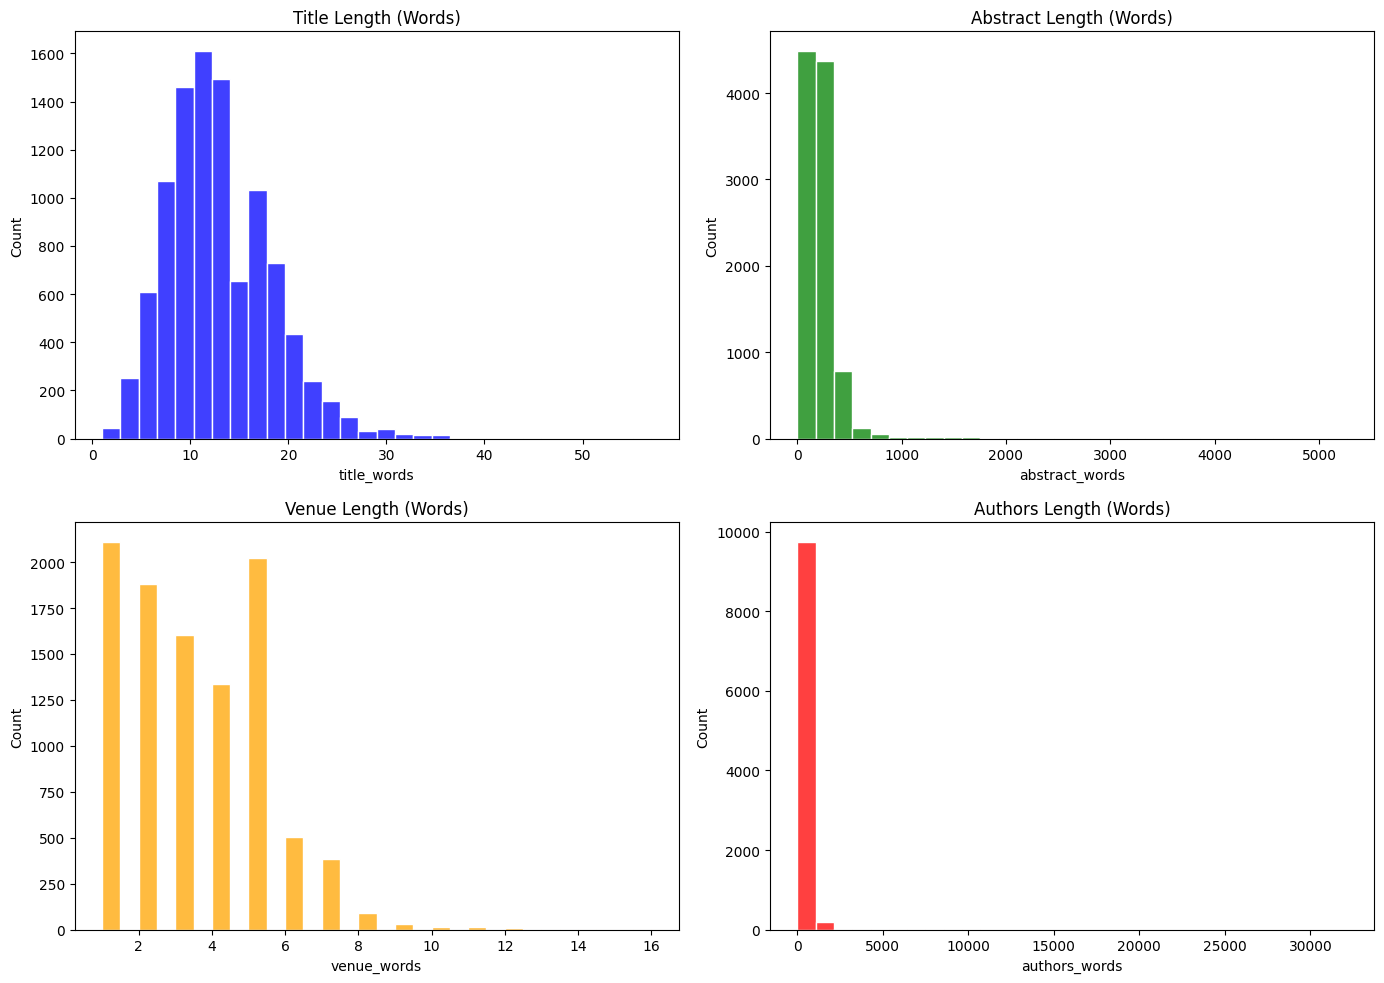

In [8]:
# word counts for the 4 text columns
df_collection['title_words'] = df_collection['title'].apply(lambda x: len(str(x).split()))
df_collection['abstract_words'] = df_collection['abstract'].apply(lambda x: len(str(x).split()))
df_collection['venue_words'] = df_collection['venue'].apply(lambda x: len(str(x).split()))
df_collection['authors_words'] = df_collection['authors'].apply(lambda x: len(str(x).split()))

# 2x2 grid for the plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.set_theme(style="whitegrid")

# plot each distribution
sns.histplot(df_collection['title_words'], bins=30, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Title Length (Words)')

sns.histplot(df_collection['abstract_words'], bins=30, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Abstract Length (Words)')

sns.histplot(df_collection['venue_words'], bins=30, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Venue Length (Words)')

sns.histplot(df_collection['authors_words'], bins=30, ax=axes[1, 1], color='red')
axes[1, 1].set_title('Authors Length (Words)')


plt.tight_layout()
plt.show()

In [11]:
# statistical summary
print("Quick Summary of Word Counts:")
print(df_collection[['title_words', 
                     'abstract_words', 
                     'venue_words', 
                     'authors_words']].describe().loc[['mean', 'max', 'min']])

Quick Summary of Word Counts:
      title_words  abstract_words  venue_words  authors_words
mean       12.965        232.4302        3.327       236.5889
max        57.000       5262.0000       16.000     32113.0000
min         1.000          1.0000        1.000         1.0000


Now I need to go in deep for each attribute:
### Title
From the previous histogram, we can do the following observations:
* the shape is close to the bell shape, slightly right tail. It is highly likely that the title field contains highly specific words. So maybe we can weight more the title if a word match the query.
* we can't detect the language from the title
* the shortest title is composed by 1 words, it's strange and so I will check soon: 

In [13]:
df_collection[df_collection['title_words'] <= 2]['title']

415                   Sweden's gamble
616                Plant intelligence
747                        Pedophilia
1372                      Red Herring
1378         Eosinophilic Esophagitis
1451               Abolition medicine
1523                      Myocarditis
1855                  Long-Haul COVID
2238          Marginal-Zone Lymphomas
2668            Self-inflicted wounds
2877           Agroecology landscapes
2895    State-of-the-Art Biocatalysis
3017                   Cytokine Storm
3858                    Medical Masks
4240                Extracellular RNA
4396                  Resident Report
4967                       Retraction
5167                 Antebellum Islam
5232                   Technopopulism
5241            Unclearing Microscopy
5427               Viral quasispecies
5984         Point-and-Shoot Memories
5987                   Abortion Pills
6203                  Hybrid immunity
6244                       Pedophilia
6676        Parsonage-Turner Syndrome
6977        

Notes:
* there are very short titles and they are also in different languages
* long words and very specific (such as *Cholangiocarcinoma*) or ambiguos (*Dear Teacher*, in the specific the abstract repeat the title but..."*Dear teacher, you are appreciated! This inspirational book, written by motivational speakers Brad Johnson and Hal Bowman, provides daily encouragement to thank you for all that...*")
* I discovered that suggested an interesting insights:
      *Retraction* means that the paper has no correct data, so this means that the real content is written in the abstract([https://en.wikipedia.org/wiki/Retraction_in_academic_publishing])

Now we will take a look at those title that are long...

In [23]:
# to see the completed text
pd.set_option('display.max_colwidth', None)

df_collection[df_collection['title_words'] >= 45][['pubkey', 'title']]

,pubkey,title
1717,2980,"Optimal follow-up after acute pulmonary embolism: a position paper of the European Society of Cardiology Working Group on Pulmonary Circulation and Right Ventricular Function, in collaboration with the European Society of Cardiology Working Group on Atherosclerosis and Vascular Biology, endorsed by the European Respiratory Society"
2137,162,"European guidelines on chronic mesenteric ischaemia – joint United European Gastroenterology, European Association for Gastroenterology, Endoscopy and Nutrition, European Society of Gastrointestinal and Abdominal Radiology, Netherlands Association of Hepatogastroenterologists, Hellenic Society of Gastroenterology, Cardiovascular and Interventional Radiological Society of Europe, and Dutch Mesenteric Ischemia Study group clinical guidelines on the diagnosis and treatment of patients with chronic…"
5651,7538,"Severe fatigue as symptom of long COVID is characterized by increased expression of inflammatory genes in monocytes, increased serum pro-inflammatory cytokines, and increased CD8+ T-lymphocytes: A putative dysregulation of the immune-brain axis, the coagulation process, and auto-inflammation to explain the diversity of long COVID symptoms"


Notes:
* many specific words
* a lot of noise (the article on *European guidelines on chronic mesenteric ischaemia* lists all the participants in the titles or act like a mini abstract)
* if we weight long title BIM25 can penalise these documents
* we need to consider a strong cleaning (stopwords, and other words)

### Abstract
We understood the importance that can play the abstrct when we have a very short. From the previuos statistics:
* **Mean**: 232 words
* **Min**: 1 word
* **Max**: 5,262 words
We are going to see both short and long abstracts:

In [30]:
df_collection[df_collection['abstract_words'] <= 10][['pubkey', 'abstract']]

,pubkey,abstract
34,9366,"Considerably transformed""-changing the narrative on admitting older patients"
81,5350,The Independent Scientific Advisory Group for Emergencies (Independent SAGE
307,2587,No therapies for targeting
505,2227,"Reinfection, seasonality, and viral competition will shape endemic transmission patterns"
535,119,Commentary p 865
...,...,...
9733,5240,Vaccinating children
9744,9523,None.
9761,6237,"EDITORIAL article Front. Psychiatry, 30 October 2020 | https://doi.org/10.3389/fpsyt.2020.600283"
9790,168,appears neither logical nor beneficial to patients.


In [37]:
# let's see how many have less than X words
short_abstracts_10 = df_collection[df_collection['abstract_words'] <= 10]
print(f"Total papers with <10 word abstracts: {len(short_abstracts_10)}that is {len(short_abstracts_10)/100}%")


short_abstracts_15 = df_collection[df_collection['abstract_words'] <= 20]
print(f"Total papers with <15 word abstracts: {len(short_abstracts_15)} that is {len(short_abstracts_15)/100}%")


short_abstracts_20 = df_collection[df_collection['abstract_words'] <= 20]
print(f"Total papers with <20 word abstracts: {len(short_abstracts_20)} that is {len(short_abstracts_20)/100}%")

Total papers with <10 word abstracts: 122that is 1.22%
Total papers with <15 word abstracts: 396 that is 3.96%
Total papers with <20 word abstracts: 396 that is 3.96%


In [38]:
long_abstracts = df_collection[df_collection['abstract_words'] >= 1000]
print(f"Total papers with >1000 word abstracts: {len(long_abstracts)}")

long_abstracts = df_collection[df_collection['abstract_words'] >= 2000]
print(f"Total papers with >2000 word abstracts: {len(long_abstracts)}")

long_abstracts = df_collection[df_collection['abstract_words'] >= 3000]
print(f"Total papers with >3000 word abstracts: {len(long_abstracts)}")

NameError: name 'df_corpus' is not defined

In [2]:
# Load the English queries
df_queries = pd.read_json('/app/experiment/docs/en_dev.jsonl', lines=True)

# Look at the first 5 tweets
display(df_queries.head())

,index,text,pubkey
0,3,Nicotine & SARS-CoV-2 COVID-19 could be a diso...,2764
1,4,"@user Correlation isn’t causation, yet it’s th...",4854
2,11,@USBornNRaised Children need unrestricted oxyg...,1210
3,15,Multidecadal oscillations in the preindustrial...,9737
4,18,Stellar (academic) piece on 'The Postcolonial ...,4138


In [6]:
# Ensure consistent language detection
DetectorFactory.seed = 0 

# Set graph styling
sns.set_theme(style="whitegrid")

print("Loading data...")
DATA_DIR = '/app/experiment'

# 1. Load the papers
corpus_path = os.path.join(DATA_DIR, 'corpus/collection.jsonl')
df_corpus = pd.read_json(corpus_path, lines=True)
print(f"✅ Loaded {len(df_corpus)} papers.")

# 2. Load and combine all queries
query_files = {
    'en': ['docs/en_train.jsonl', 'docs/en_dev.jsonl'],
    'de': ['docs/de_train.jsonl', 'docs/de_dev.jsonl'],
    'fr': ['docs/fr_train.jsonl', 'docs/fr_dev.jsonl']
}

all_queries = []
for lang, files in query_files.items():
    for file in files:
        path = os.path.join(DATA_DIR, file)
        if os.path.exists(path):
            df_temp = pd.read_json(path, lines=True)
            df_temp['lang'] = lang
            df_temp['split'] = 'train' if 'train' in file else 'dev'
            all_queries.append(df_temp)

df_queries = pd.concat(all_queries, ignore_index=True)
print(f"✅ Loaded {len(df_queries)} total queries across {df_queries['lang'].nunique()} languages.")

Loading data...
✅ Loaded 10000 papers.
✅ Loaded 24237 total queries across 3 languages.


🎯 Targeted Papers (Have at least 1 query): 5923
👻 Distractor Papers (Zero queries): 4077
🔥 The most debated paper (pubkey 7413) has 172 queries pointing to it!



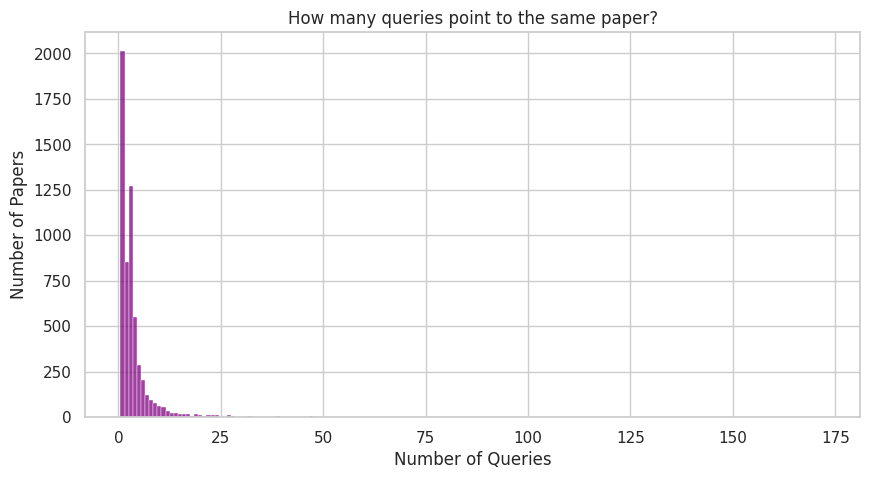

🌍 Papers targeted by queries in multiple languages: 1651


In [7]:
# 1. Find how many queries point to each paper
hub_papers = df_queries.groupby('pubkey').size().reset_index(name='query_count')
hub_papers = hub_papers.sort_values('query_count', ascending=False)

# 2. Merge this info back into the corpus dataframe
df_corpus = df_corpus.merge(hub_papers, on='pubkey', how='left')
df_corpus['query_count'] = df_corpus['query_count'].fillna(0).astype(int)

# 3. Calculate Target vs Distractor ratio
targeted_papers = len(df_corpus[df_corpus['query_count'] > 0])
distractor_papers = len(df_corpus[df_corpus['query_count'] == 0])

print(f"🎯 Targeted Papers (Have at least 1 query): {targeted_papers}")
print(f"👻 Distractor Papers (Zero queries): {distractor_papers}")
print(f"🔥 The most debated paper (pubkey {hub_papers.iloc[0]['pubkey']}) has {hub_papers.iloc[0]['query_count']} queries pointing to it!\n")

# Plot the distribution of queries per targeted paper
plt.figure(figsize=(10, 5))
sns.histplot(data=hub_papers, x='query_count', discrete=True, color='purple')
plt.title('How many queries point to the same paper?')
plt.xlabel('Number of Queries')
plt.ylabel('Number of Papers')
plt.show()

# Show cross-lingual targets (Papers asked about in multiple languages)
multi_lang_papers = df_queries.groupby('pubkey')['lang'].nunique().reset_index(name='lang_count')
print(f"🌍 Papers targeted by queries in multiple languages: {len(multi_lang_papers[multi_lang_papers['lang_count'] > 1])}")

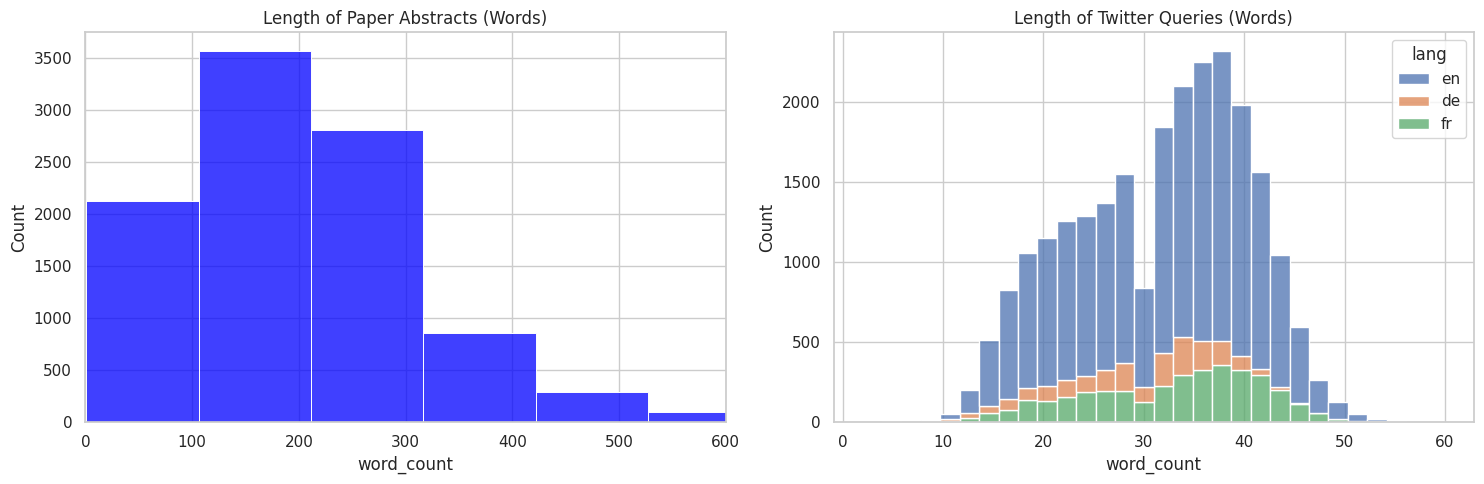

Detecting languages of papers (Sampling 5000 docs)...


Detecting Language:   0%|          | 0/10000 [00:00<?, ?it/s]

/tmp/ipykernel_42/1290441052.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lang_counts.index, y=lang_counts.values, palette="viridis")


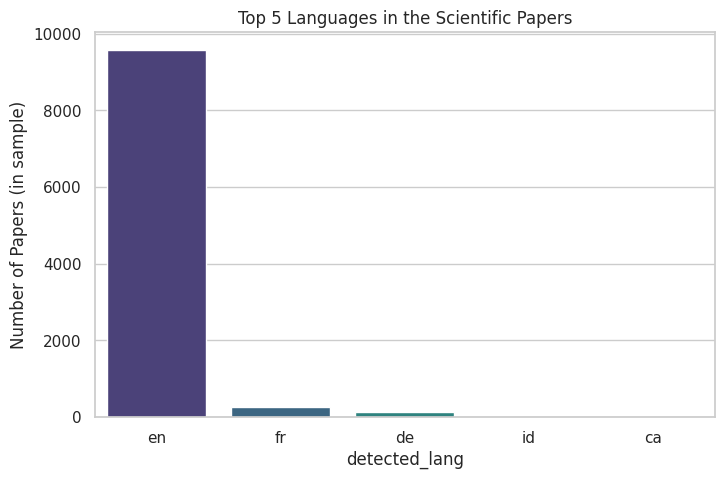

In [9]:
# 1. Analyze Document and Query Lengths
df_corpus['word_count'] = df_corpus['abstract'].astype(str).apply(lambda x: len(x.split()))
df_queries['word_count'] = df_queries['text'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_corpus[df_corpus['word_count'] > 0]['word_count'], bins=50, ax=axes[0], color='blue')
axes[0].set_title('Length of Paper Abstracts (Words)')
axes[0].set_xlim(0, 600)

sns.histplot(data=df_queries, x='word_count', hue='lang', multiple="stack", bins=30, ax=axes[1])
axes[1].set_title('Length of Twitter Queries (Words)')

plt.tight_layout()
plt.show()

# 2. Detect Paper Languages
# (We will only sample 5,000 random papers to save time, you can remove '.sample(5000)' to do all of them)
print("Detecting languages of papers (Sampling 5000 docs)...")
sample_docs = df_corpus.dropna(subset=['abstract']).sample(5000*2, random_state=42)

def safe_detect(text):
    try:
        return detect(text[:500]) # Look at first 500 chars for speed
    except:
        return 'unknown'

tqdm.pandas(desc="Detecting Language")
sample_docs['detected_lang'] = sample_docs['abstract'].progress_apply(safe_detect)

# Plot the language distribution
plt.figure(figsize=(8, 5))
lang_counts = sample_docs['detected_lang'].value_counts().head(5)
sns.barplot(x=lang_counts.index, y=lang_counts.values, palette="viridis")
plt.title('Top 5 Languages in the Scientific Papers')
plt.ylabel('Number of Papers (in sample)')
plt.show()

## Try to see if code works

In [ ]:
import sys
# production code path if we want to import some piece of code
sys.path.insert(0, '/app/src') 